In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *



import matplotlib as mpl
mpl.rcParams["font.size"] = 18

dir_save_data = r'C:\Users\nberr\PhD\Articles\2025 - Q factor study\Figures\All figures python'

# Plot linear spectra of ND

### Spectre pour l'introduction sur la SMS

In [2]:
### Get calib

dir_calib = r'H:\commun\Utilisateur FNO\Nathan\Experimental\Calibration\Nanoscope 2\March 2025\ND4-1-col2\Calib_finale'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']


#Get spectra
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3' 

Spectra_Data['ND'] = Spectra_computation(dir_root1, 'Other linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '21-Jan-2025-Spectre_theta_0', force_recomputation=False, spectra_title = '21-Jan-2025-Spectre_theta_0', method='fine')
Spectra_Data['ND2'] = Spectra_computation(dir_root1, 'Other linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '21-Jan-2025-Spectre_theta_90', force_recomputation=False, spectra_title = '21-Jan-2025-Spectre_theta_90', method='fine')

data = Spectra_Data['ND']
data2 = Spectra_Data['ND2']

Other linear spectra already treated
Other linear spectra already treated


C:\Users\nberr\AppData\Local\Temp\ipykernel_16088\3511102602.py:51: RuntimeWarning:

divide by zero encountered in divide



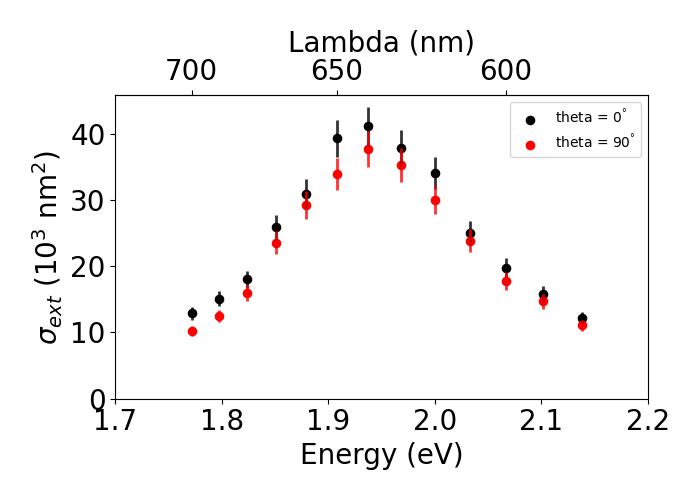

In [ ]:
mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize=(7,5))    




L1 = [data['Lambda'][kkey] for kkey in data['Lambda']]
All_lambda = np.concatenate(L1)
E_min = 1240/((np.max(All_lambda)*1e9))-0.1
E_max = 1240/(np.min(All_lambda)*1e9)+0.1



E = np.linspace(E_min, E_max, 1000)


idx_begin = -2
idx_end = 3

for source_key in ['OPO'] :

    plt.scatter(1240/(data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15,s = 35,color='black', label=r"theta = 0$^\degree$")
    plt.errorbar(1240/(data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15, yerr = data['Sigma_err'][source_key][idx_end:idx_begin]*1e15, linestyle='',alpha=0.8, linewidth=2,color='black')



    plt.scatter(1240/(data2['Lambda'][source_key][idx_end:idx_begin]*1e9), data2['Sigma'][source_key][idx_end:idx_begin]*1e15,s = 35,color='red', label=r"theta = 90$^\degree$")
    plt.errorbar(1240/(data2['Lambda'][source_key][idx_end:idx_begin]*1e9), data2['Sigma'][source_key][idx_end:idx_begin]*1e15, yerr = data2['Sigma_err'][source_key][idx_end:idx_begin]*1e15, linestyle='',alpha=0.8, linewidth=2,color='red')



    #plt.plot(E, Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A'])*1e15, color="#DB0000")
    #plt.axvline(E[np.argmax(Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A']))], color='black', linestyle='--')
    #plt.text(2.01, 5, r'$\lambda_{SPR}$')

#ax.text(0.45, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
#plt.axvline(1240/640, linestyle='--',alpha=0.5, color='black')


plt.ylim(bottom = 0)


plt.legend(fontsize=10)
plt.xlim((1.7, 2.2))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel('Energy (eV)')



def convert(x) :
    return 1240/x

ax2 = ax.secondary_xaxis("top", functions=(convert, convert))

ax2.set_xlabel("Lambda (nm)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()

fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)
plt.savefig('ND Spectra (Energy) - sapphire ND d zone 3.svg')


C:\Users\nberr\AppData\Local\Temp\ipykernel_16088\1910835185.py:51: RuntimeWarning:

divide by zero encountered in divide



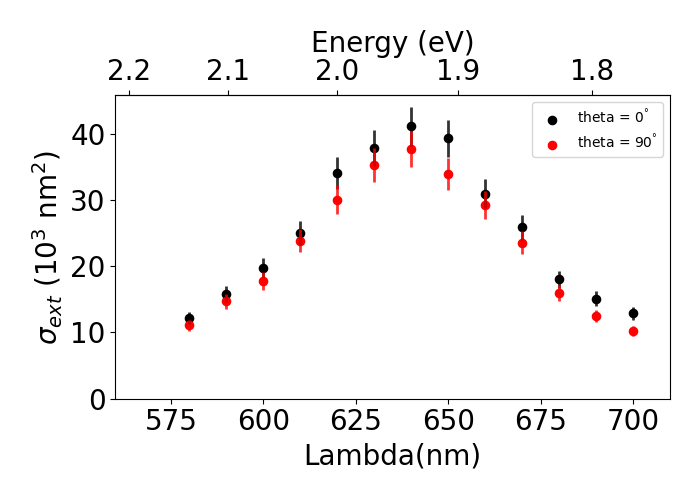

In [4]:
mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize=(7,5))    




L1 = [data['Lambda'][kkey] for kkey in data['Lambda']]
All_lambda = np.concatenate(L1)
E_min = 1240/((np.max(All_lambda)*1e9))-0.1
E_max = 1240/(np.min(All_lambda)*1e9)+0.1



E = np.linspace(E_min, E_max, 1000)


idx_begin = -2
idx_end = 3

for source_key in ['OPO'] :

    plt.scatter((data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15,s = 35,color='black', label=r"theta = 0$^\degree$")
    plt.errorbar((data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15, yerr = data['Sigma_err'][source_key][idx_end:idx_begin]*1e15, linestyle='',alpha=0.8, linewidth=2,color='black')



    plt.scatter((data2['Lambda'][source_key][idx_end:idx_begin]*1e9), data2['Sigma'][source_key][idx_end:idx_begin]*1e15,s = 35,color='red', label=r"theta = 90$^\degree$")
    plt.errorbar((data2['Lambda'][source_key][idx_end:idx_begin]*1e9), data2['Sigma'][source_key][idx_end:idx_begin]*1e15, yerr = data2['Sigma_err'][source_key][idx_end:idx_begin]*1e15, linestyle='',alpha=0.8, linewidth=2,color='red')



    #plt.plot(E, Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A'])*1e15, color="#DB0000")
    #plt.axvline(E[np.argmax(Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A']))], color='black', linestyle='--')
    #plt.text(2.01, 5, r'$\lambda_{SPR}$')

#ax.text(0.45, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
#plt.axvline(1240/640, linestyle='--',alpha=0.5, color='black')


plt.ylim(bottom = 0)


plt.legend(fontsize=10)
plt.xlim((560, 710))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel('Lambda(nm)')



def convert(x) :
    return 1240/x

ax2 = ax.secondary_xaxis("top", functions=(convert, convert))

ax2.set_xlabel("Energy (eV)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)

plt.savefig('ND Spectra (wavelength) - sapphire ND d zone 3.svg')

## Same for Silice thick 4,5 - D1 zone1

Linear spectra already treated
Linear spectra already treated


C:\Users\nberr\AppData\Local\Temp\ipykernel_16088\3551348336.py:75: RuntimeWarning:

divide by zero encountered in divide



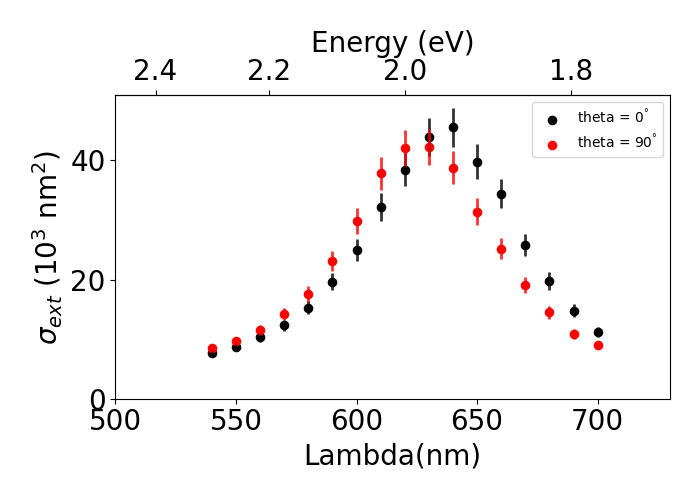

In [5]:
### Get calib

dir_calib = r'H:\commun\Utilisateur FNO\Nathan\Experimental\Calibration\Nanoscope 2\March 2025\ND4-1-col2\Calib_finale'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']


#Get spectra
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D1 zone1' 

Spectra_Data['ND'] = Spectra_computation(dir_root1, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '01-Jul-2025-Spectre_theta_80', force_recomputation=False,  method='fine')
Spectra_Data['ND2'] = Spectra_computation(dir_root1, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '01-Jul-2025-Spectre_theta_170', force_recomputation=False,  method='fine')

data = Spectra_Data['ND']
data2 = Spectra_Data['ND2']



mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize=(7,5))    




L1 = [data['Lambda'][kkey] for kkey in data['Lambda']]
All_lambda = np.concatenate(L1)
E_min = 1240/((np.max(All_lambda)*1e9))-0.1
E_max = 1240/(np.min(All_lambda)*1e9)+0.1



E = np.linspace(E_min, E_max, 1000)


idx_begin = -2
idx_end = 3

for source_key in ['OPO'] :

    plt.scatter((data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15,s = 35,color='black', label=r"theta = 0$^\degree$")
    plt.errorbar((data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15, yerr = data['Sigma_err'][source_key][idx_end:idx_begin]*1e15, linestyle='',alpha=0.8, linewidth=2,color='black')



    plt.scatter((data2['Lambda'][source_key][idx_end:idx_begin]*1e9), data2['Sigma'][source_key][idx_end:idx_begin]*1e15,s = 35,color='red', label=r"theta = 90$^\degree$")
    plt.errorbar((data2['Lambda'][source_key][idx_end:idx_begin]*1e9), data2['Sigma'][source_key][idx_end:idx_begin]*1e15, yerr = data2['Sigma_err'][source_key][idx_end:idx_begin]*1e15, linestyle='',alpha=0.8, linewidth=2,color='red')



    #plt.plot(E, Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A'])*1e15, color="#DB0000")
    #plt.axvline(E[np.argmax(Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A']))], color='black', linestyle='--')
    #plt.text(2.01, 5, r'$\lambda_{SPR}$')

#ax.text(0.45, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
#plt.axvline(1240/640, linestyle='--',alpha=0.5, color='black')


plt.ylim(bottom = 0)


plt.legend(fontsize=10)
plt.xlim((500, 730))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel('Lambda(nm)')



def convert(x) :
    return 1240/x

ax2 = ax.secondary_xaxis("top", functions=(convert, convert))

ax2.set_xlabel("Energy (eV)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)

plt.savefig('ND Spectra (wavelength) - Silice thick D1 zone1.svg')

# Plot PaP signal without treatment

In [6]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_670'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

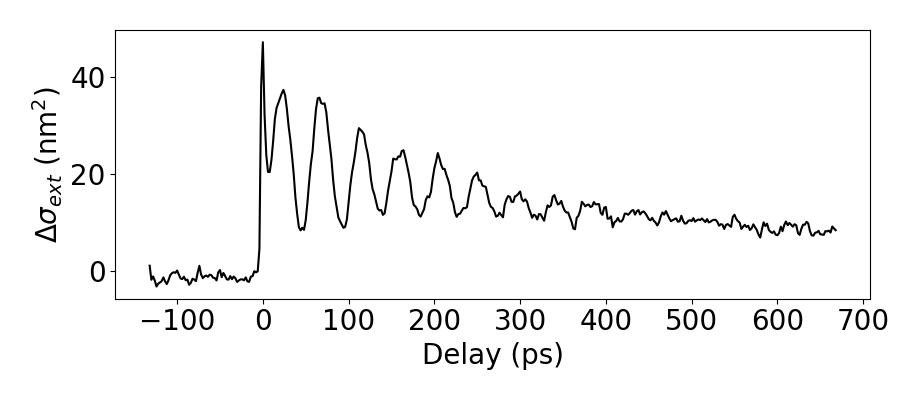

In [7]:
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -179018.682874547 #conversion coefficient from DTT to delta sigma in nm2

mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize = (9,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*alpha_DTT_dsigma,  color = 'black')


ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP total signal on sapphire - quantitative.svg')

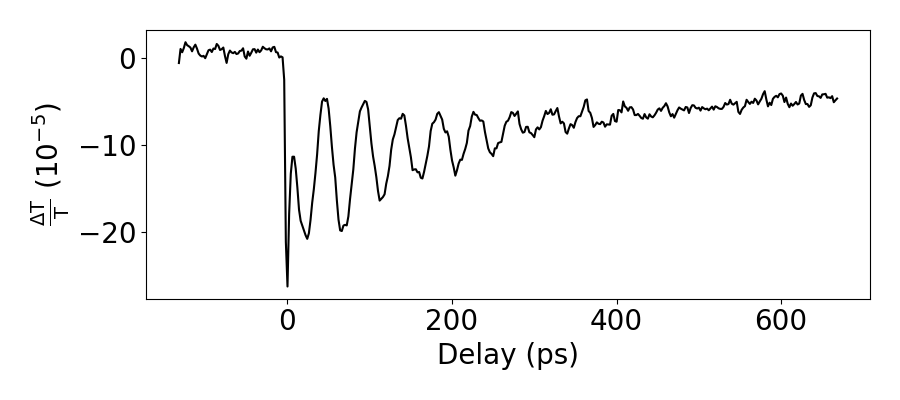

In [8]:
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -179018.682874547 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = 1e5 #conversion coefficient from DTT to delta sigma in nm2

mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize = (9,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*alpha_DTT_dsigma,  color = 'black')


ax.set_ylabel(r'$\frac{\Delta \mathrm{T}}{\mathrm{T}}$ (10$^{-5}$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP total signal on sapphire - DTT.svg')

C:\Users\nberr\AppData\Local\Temp\ipykernel_16088\1837174906.py:12: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_16088\1837174906.py:12: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.



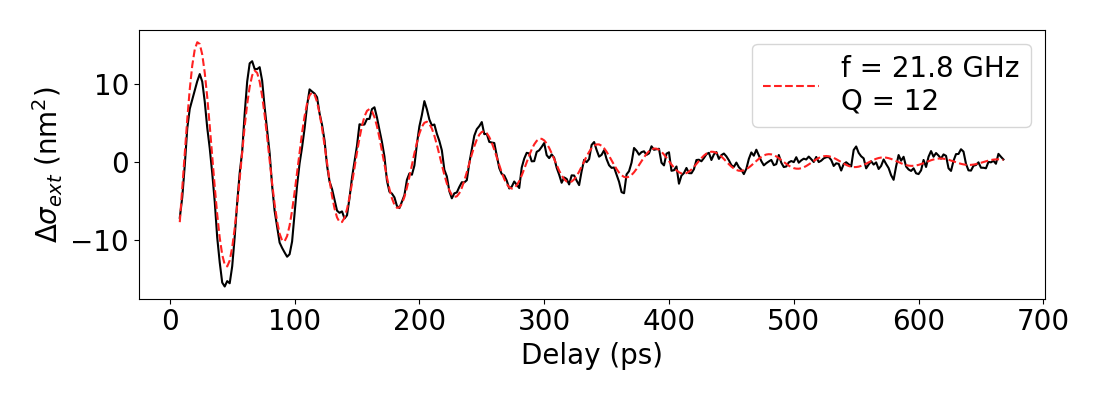

In [9]:
mpl.rcParams["font.size"] = 20
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -179018.682874547 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay, Trace.DTT_acoustic*alpha_DTT_dsigma,  color = 'black')


ax.plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 21.8 GHz' +  "\n" + 'Q = 12')



ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.legend(fontsize=20)
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP acoustic signal on sapphire.svg')

## same for Silice - thick

C:\Users\nberr\AppData\Local\Temp\ipykernel_16088\883606273.py:57: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_16088\883606273.py:57: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.



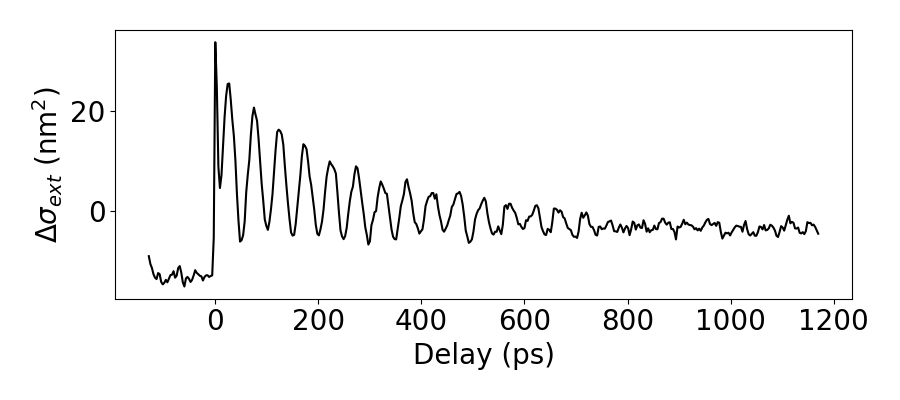

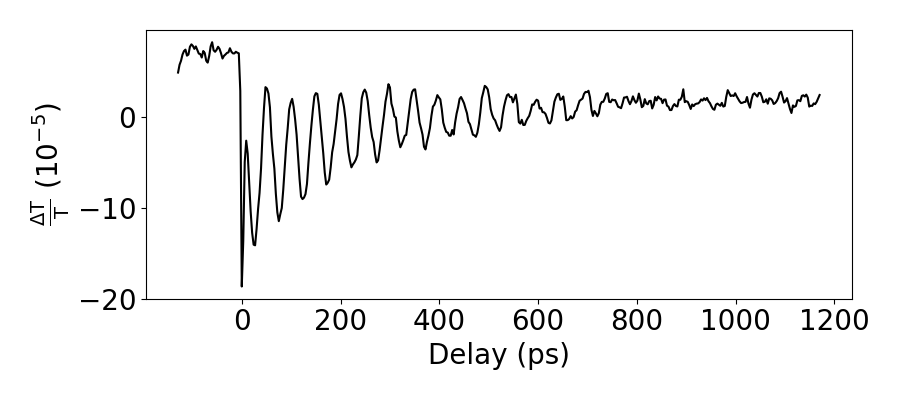

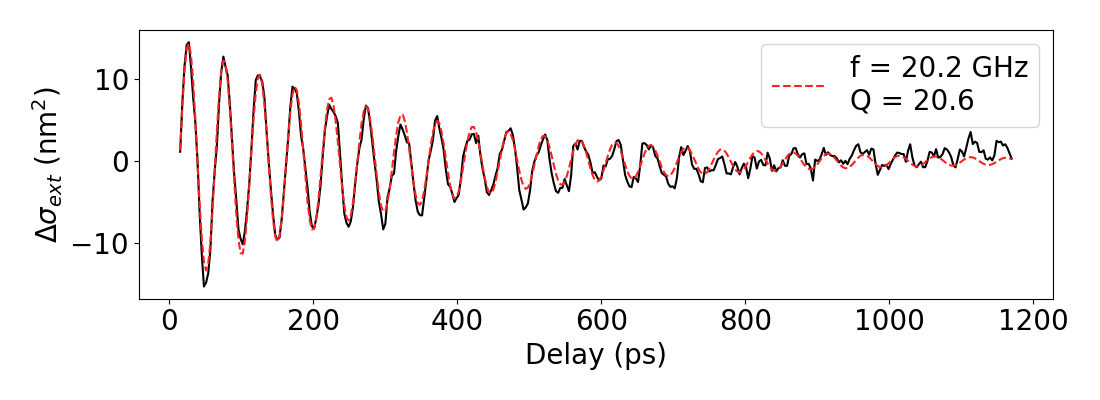

In [10]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D1 zone1\PaP_study'
dir_name = r'11-Jul-2025_PaP_Pp6uW_ldap410nm_ldas_650'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)



alpha_DTT_dsigma = -180272.23443 #conversion coefficient from DTT to delta sigma in nm2

mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize = (9,4))
#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*alpha_DTT_dsigma,  color = 'black')
ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()

os.chdir(dir_save_data)
plt.savefig('PaP total signal on thick silice - quantitative.svg')




mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize = (9,4))
#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*1e5,  color = 'black')
ax.set_ylabel(r'$\frac{\Delta \mathrm{T}}{\mathrm{T}}$ (10$^{-5}$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()

os.chdir(dir_save_data)
plt.savefig('PaP total signal on thick silice - DTT.svg')




mpl.rcParams["font.size"] = 20
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -179018.682874547 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay, Trace.DTT_acoustic*alpha_DTT_dsigma,  color = 'black')
ax.plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20.2 GHz' +  "\n" + 'Q = 20.6')
ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.legend(fontsize=20)
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP acoustic signal on thick silica.svg')

## Quality factor study

### Get all relevant data

In [11]:
path = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet'

Simu_Data = {}
Simu_SPR_data = {}
Exp_Data = {}
Plot_dic = {}
Points = {}

# Sapphire result
key_1 = 'Sapphire'

Simu_Data[key_1] = {}

sample_name_1 = r'\Sapphire'
root_simu_1 = path + sample_name_1 + r'\AR_estimation\SPR_simu_treated'
fname_data_simu_1 = 'Treated_simulations'
Simu_SPR_data[key_1], Simu_Data[key_1]['Lda_RBF'], Simu_Data[key_1]['E_RBF'], Simu_Data[key_1]['W_RBF'], Simu_Data[key_1]['Aire_RBF'], Points[key_1] = get_simu_data_and_interpolate(root_simu_1, fname_data_simu_1, kernel='linear')

root_exp_1 = path + sample_name_1 + r'\AR_estimation\ND_measurements_AR_treated'
fname_data_exp_1 = 'Treated_data'
Exp_Data[key_1] = get_treated_AR_data(root_exp_1, fname_data_exp_1)

Plot_dic[key_1] = {}
Plot_dic[key_1]['main'] = "#377eb8"
Plot_dic[key_1]['marker'] = "o"

# Silice - thick results
key_2 = 'Silice - thick'

Simu_Data[key_2] = {}

sample_name_2 = r'\Silice - thick'
root_simu_2 = path + sample_name_2 + r'\AR_estimation\SPR_simu_treated'
fname_data_simu_2 = 'Treated_simulations'
Simu_SPR_data[key_2], Simu_Data[key_2]['Lda_RBF'], Simu_Data[key_2]['E_RBF'], Simu_Data[key_2]['W_RBF'], Simu_Data[key_2]['Aire_RBF'], Points[key_2] = get_simu_data_and_interpolate(root_simu_2, fname_data_simu_2, kernel='linear')

root_exp_2 = path + sample_name_2 + r'\AR_estimation\ND_measurements_AR_treated'
fname_data_exp_2 = 'Treated_data'
Exp_Data[key_2] = get_treated_AR_data(root_exp_2, fname_data_exp_2)

Plot_dic[key_2] = {}
Plot_dic[key_2]['main'] = '#984ea3'
Plot_dic[key_2]['marker'] = "H"
# Silice - membrane results
key_3 = 'Silice - membrane'

Simu_Data[key_3] = {}

sample_name_3 = r'\Silice - membrane'
root_simu_3 = path + sample_name_3 + r'\AR_estimation\SPR_simu_treated'
fname_data_simu_3 = 'Treated_simulations'
Simu_SPR_data[key_3], Simu_Data[key_3]['Lda_RBF'], Simu_Data[key_3]['E_RBF'], Simu_Data[key_3]['W_RBF'], Simu_Data[key_3]['Aire_RBF'], Points[key_3] = get_simu_data_and_interpolate(root_simu_3, fname_data_simu_3, kernel='linear')

root_exp_3 = path + sample_name_3 + r'\AR_estimation\ND_measurements_AR_treated'
fname_data_exp_3 = 'Treated_data'
Exp_Data[key_3] = get_treated_AR_data(root_exp_3, fname_data_exp_3)

Plot_dic[key_3] = {}
Plot_dic[key_3]['main'] = "#4daf4a"
Plot_dic[key_3]['marker'] = "v"



Sapphire
Silice - thick
Silice - membrane


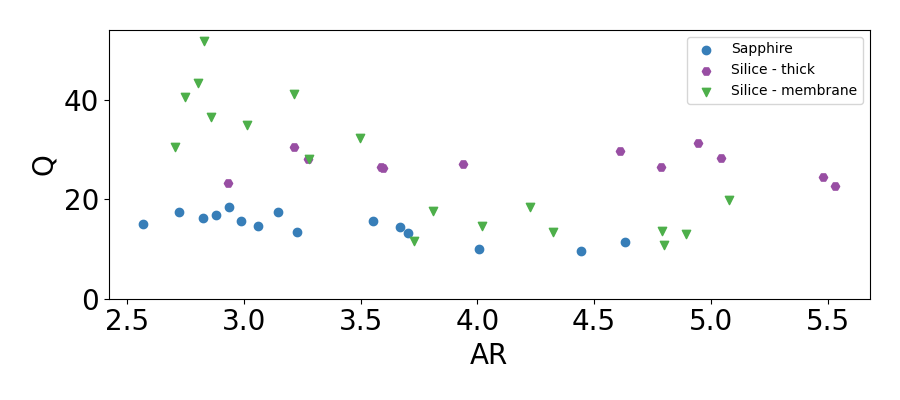

In [12]:
fig, ax = plt.subplots(figsize = (9,4))
ax.set_xlabel('AR')
ax.set_ylabel('Q')

for key in Exp_Data :
    print(key)
    exp_data = Exp_Data[key]
   
    
    idx = np.where(np.array([exp_data[kkey]['Q'] for kkey in exp_data]) != 0)[0]

    X = np.array([exp_data[kkey]['1D']['AR'] for kkey in exp_data])[idx]
    Y = np.array([exp_data[kkey]['Q'] for kkey in exp_data])[idx]


    
    plt.scatter(X, Y, color=Plot_dic[key]['main'], marker =Plot_dic[key]['marker'] , label = key)
    
ax.set_ylim(bottom=0)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)

plt.savefig('Q_factor_study_big.svg')


small version

### 2 PaP signal for same ND geometry

### Compoisition effect : NDb zone-Sylvie (Sapphire) / ND7 zone 1 (Silice thick)

In [13]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR2.3\zone1\NDb'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'02-Dec-2024_PaP_Pp6uW_ldap410nm_ldas630nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'





Trace_NDb = get_PaP_dataset(dir_root + '\\' + dir_name, filename)


dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR 4,5\zone-1\D7'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'04-Apr-2025_PaP_Pp6uW_ldap410nm_ldas650nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_ND7 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)




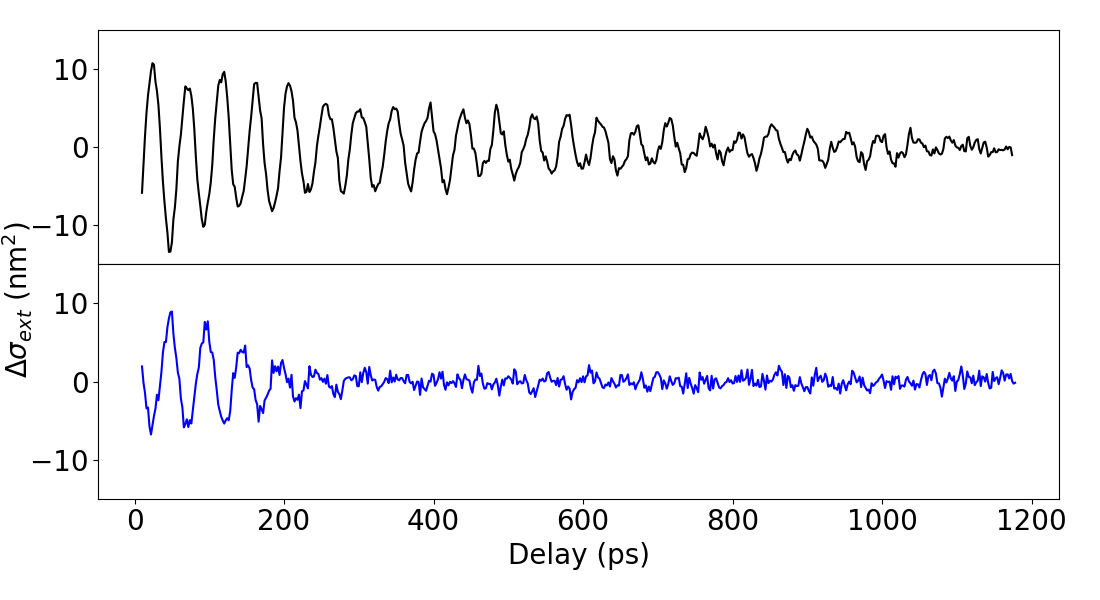

In [14]:
coeff_NDb = -169173.92653200435 #conversion coefficient from DTT to delta sigma in nm2
coeff_ND7 = -172035.5417065772


mpl.rcParams["font.size"] = 20
fig,ax = plt.subplots(figsize=(11, 6),nrows=2, sharex=True)
# set height ratios for subplots





#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax[0].plot(Trace_ND7.delay, Trace_ND7.DTT_acoustic*coeff_ND7,  color = 'black')
#ax[0].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


ax[1].plot(Trace_NDb.delay, Trace_NDb.DTT_acoustic*coeff_NDb,  color = 'blue')


ax[1].set_ylim((-15, 15))
ax[0].set_ylim((-15, 15))

ax[1].set_xlabel('Delay (ps)')
plt.tight_layout()
fig.text(0, 0.5, r'$\Delta \sigma_{ext}$ (nm$^2$)', va='center', rotation='vertical')


plt.subplots_adjust(hspace=.0)
#ax[1].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
plt.savefig('2 PaP signals - composition effect.svg')




### Geometry effect : ND6 AR4.5 (Silice thin) / D5 zone 1 (Silice thick)

In [15]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - membrane\AR4.5gridA5\AR4.5-6\20231219_pr600nm_pp410nm_Ppp=3uw_pol-12'
dir_name = r'Traces'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'





Trace_ND6 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)


dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR 4,5\zone-1\D5'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'03-Apr-2025_PaP_Pp6uW_ldap410nm_ldas650nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_ND5 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

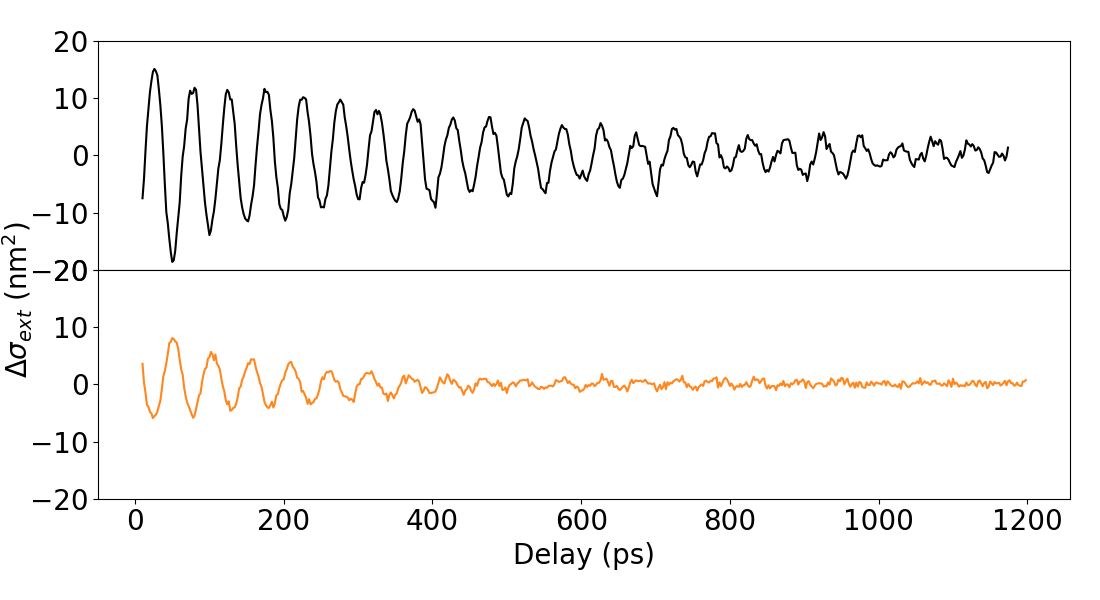

In [16]:
coeff_ND6 = -154624.64077338015 #conversion coefficient from DTT to delta sigma in nm2
coeff_ND5 = -172035.5417065772


mpl.rcParams["font.size"] = 20
fig,ax = plt.subplots(figsize=(11, 6),nrows=2, sharex=True)
# set height ratios for subplots





#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax[0].plot(Trace_ND5.delay, Trace_ND5.DTT_acoustic*coeff_ND5,  color = 'black')
#ax[0].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


ax[1].plot(Trace_ND6.delay[:np.argwhere(Trace_ND6.delay>=1200).min()], Trace_ND6.DTT_acoustic[:np.argwhere(Trace_ND6.delay>=1200).min()]*coeff_ND6,  color = "#FF871E")


ax[1].set_ylim((-20, 20))
ax[0].set_ylim((-20, 20))

ax[1].set_xlabel('Delay (ps)')
plt.tight_layout()
fig.text(0, 0.5, r'$\Delta \sigma_{ext}$ (nm$^2$)', va='center', rotation='vertical')


plt.subplots_adjust(hspace=.0)
#ax[1].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
plt.savefig('2 PaP signals - geometry effect.svg')
